# Análisis exploratorio de créditos

## Comprensión del negocio

Una entidad que otorga créditos necesita conocer las características
asociadas al cumplimiento de pago de sus clientes.

El objetivo del proyecto es analizar los datos históricos y preparar
la información para desarrollar un modelo que prediga si un cliente
pagará a tiempo.

## Variable objetivo

La variable objetivo es Pago_atiempo. Inicialmente se interpreta:

- 1: paga a tiempo.
- 0: no paga a tiempo.

La interpretación y el periodo evaluado deben confirmarse con la
fuente de los datos.

El problema corresponde a una clasificación binaria supervisada.

In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

if ROOT.name == "mlops_pipeline":
    ROOT = ROOT.parent

df_original = pd.read_csv(ROOT / "Base_de_datos.csv")
df = df_original.copy()

print("Registros:", df.shape[0])
print("Variables:", df.shape[1])

display(df.head())

Registros: 10763
Variables: 23


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,...,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,1852560.0,12,32,Empleado,3500000,1000000,128650,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,2025-01-09 11:18:48,3181080.0,6,34,Empleado,5000000,2000000,441817,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,2024-12-26 18:52:57,670200.0,5,34,Independiente,5000000,2000000,108632,95.227787,...,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,506806.8,2,25,Independiente,3000000,900000,199684,95.227787,...,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,999780.0,10,26,Empleado,2000000,600000,92509,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


## 1. Exploración inicial y calidad de los datos

Se revisan los tipos de almacenamiento, la cantidad de valores
distintos, los datos faltantes y las filas completamente duplicadas.

Esta revisión permite identificar problemas antes de realizar
transformaciones o interpretar los gráficos.

In [2]:
df.info()

resumen_inicial = pd.DataFrame({
    "tipo_actual": df.dtypes.astype(str),
    "valores_distintos": df.nunique(),
    "cantidad_nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(2)
})

display(resumen_inicial)

print("Filas completamente duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

,tipo_actual,valores_distintos,cantidad_nulos,porcentaje_nulos
tipo_credito,int64,6,0,0.00
fecha_prestamo,str,10758,0,0.00
capital_prestado,float64,7306,0,0.00
plazo_meses,int64,18,0,0.00
edad_cliente,int64,54,0,0.00
tipo_laboral,str,2,0,0.00
salario_cliente,int64,1385,0,0.00
total_otros_prestamos,int64,1538,0,0.00
cuota_pactada,int64,9836,0,0.00
puntaje,float64,248,0,0.00


Filas completamente duplicadas: 0


## 2. Caracterización de las variables

La clasificación conceptual describe qué representa una variable.
Puede diferir del tipo con el que Python la almacena.

| Variable | Clasificación conceptual |
|---|---|
| tipo_credito | Categórica nominal politómica: sus números representan códigos |
| fecha_prestamo | Temporal: fecha y hora |
| capital_prestado | Cuantitativa monetaria |
| plazo_meses | Cuantitativa discreta |
| edad_cliente | Cuantitativa discreta, registrada en años enteros |
| tipo_laboral | Categórica nominal dicotómica |
| salario_cliente | Cuantitativa monetaria |
| total_otros_prestamos | Cuantitativa monetaria; significado y unidades por confirmar |
| cuota_pactada | Cuantitativa monetaria |
| puntaje | Cuantitativa de puntuación; escala por confirmar |
| puntaje_datacredito | Cuantitativa de puntuación; escala y códigos especiales por confirmar |
| cant_creditosvigentes | Cuantitativa discreta |
| huella_consulta | Cuantitativa discreta, si representa un número de consultas |
| saldo_mora | Cuantitativa monetaria |
| saldo_total | Cuantitativa monetaria |
| saldo_principal | Cuantitativa monetaria |
| saldo_mora_codeudor | Cuantitativa monetaria |
| creditos_sectorFinanciero | Cuantitativa discreta |
| creditos_sectorCooperativo | Cuantitativa discreta |
| creditos_sectorReal | Cuantitativa discreta |
| promedio_ingresos_datacredito | Cuantitativa monetaria |
| tendencia_ingresos | Categórica ordinal, pendiente de validar sus categorías |
| Pago_atiempo | Categórica dicotómica: variable objetivo |

Las variables monetarias se tratarán como cantidades continuas
para el análisis. Sus unidades deben confirmarse con la fuente.
Las categorías ordinales tienen un orden; las nominales no.

In [3]:
for columna in [
    "tipo_credito",
    "tipo_laboral",
    "tendencia_ingresos",
    "Pago_atiempo"
]:
    print(f"\nVariable: {columna}")
    display(df[columna].value_counts(dropna=False))


Variable: tipo_credito


tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64


Variable: tipo_laboral


tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64


Variable: tendencia_ingresos


tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
168750            1
-28589            1
-566272           1
24702             1
31837             1
122727            1
417087            1
9090              1
173031            1
-70715            1
-435177           1
-702927           1
-4105             1
54683             1
22832             1
209090            1
5697              1
-288              1
-164315           1
2029000           1
17181             1
15245             1
82657             1
52862             1
1817052           1
75761             1
146918            1
1123000           1
15090             1
4250635           1
22363             1
-101368           1
86286             1
65988             1
77975             1
-224714           1
10808             1
Name: count, dtype: int64


Variable: Pago_atiempo


Pago_atiempo
1    10252
0      511
Name: count, dtype: int64

## 3. Preparación y revisión de calidad

Se unifican las representaciones de valores faltantes y se ajustan
los tipos de datos.

Los valores inesperados de tendencia_ingresos se tratarán
provisionalmente como faltantes. No se eliminarán registros
ni se reemplazarán todos los nulos por cero.

In [4]:
import numpy as np

# Unificar espacios vacíos y marcadores de información faltante.
df = df.replace(
    r"(?i)^\s*(?:na|n/a|null|none|nan)?\s*$",
    np.nan,
    regex=True
)

# Limpiar espacios en las categorías de texto.
for columna in ["tipo_laboral", "tendencia_ingresos"]:
    df[columna] = df[columna].astype("string").str.strip()

print("Representaciones de nulos unificadas.")

Representaciones de nulos unificadas.


In [5]:
tendencias_validas = ["Creciente", "Decreciente", "Estable"]

tendencias_invalidas = (
    df["tendencia_ingresos"].notna()
    & ~df["tendencia_ingresos"].isin(tendencias_validas)
)

print("Valores inesperados:", tendencias_invalidas.sum())

display(
    df.loc[tendencias_invalidas, "tendencia_ingresos"]
    .value_counts()
)

# Conservar el detalle para documentar la modificación.
registros_tendencia_invalida = df.loc[
    tendencias_invalidas
].copy()

# Corrección provisional en la copia de trabajo.
df.loc[tendencias_invalidas, "tendencia_ingresos"] = pd.NA

Valores inesperados: 58


tendencia_ingresos
0          7
8315       6
1000000    4
9147       2
158042     1
3978       1
168750     1
-28589     1
-566272    1
24702      1
31837      1
122727     1
417087     1
9090       1
173031     1
-70715     1
-435177    1
-702927    1
-4105      1
54683      1
22832      1
209090     1
5697       1
-288       1
-164315    1
2029000    1
17181      1
15245      1
82657      1
52862      1
1817052    1
75761      1
146918     1
1123000    1
15090      1
4250635    1
22363      1
-101368    1
86286      1
65988      1
77975      1
-224714    1
10808      1
Name: count, dtype: Int64

In [6]:
# Convertir la fecha y contar valores que no pudieron interpretarse.
fechas_antes = df["fecha_prestamo"].notna()

df["fecha_prestamo"] = pd.to_datetime(
    df["fecha_prestamo"],
    errors="coerce"
)

print(
    "Fechas no interpretables:",
    (fechas_antes & df["fecha_prestamo"].isna()).sum()
)

# Los códigos de crédito representan categorías, no cantidades.
df["tipo_credito"] = df["tipo_credito"].astype("category")
df["tipo_laboral"] = df["tipo_laboral"].astype("category")

# Mantener nominal hasta confirmar el orden con la fuente.
df["tendencia_ingresos"] = (
    df["tendencia_ingresos"].astype("category")
)

# Comprobar la variable objetivo antes de convertirla.
assert df["Pago_atiempo"].notna().all(), (
    "La variable objetivo contiene nulos."
)

assert df["Pago_atiempo"].isin([0, 1]).all(), (
    "La variable objetivo contiene valores diferentes de 0 y 1."
)

df["Pago_atiempo"] = df["Pago_atiempo"].astype("category")

df.info()

Fechas no interpretables: 0
<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  category      
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  category      
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11

In [7]:
alertas = pd.Series({
    "Edades superiores a 100 años":
        (df["edad_cliente"] > 100).sum(),

    "Salarios iguales a cero":
        (df["salario_cliente"] == 0).sum(),

    "Puntajes de Datacrédito negativos":
        (df["puntaje_datacredito"] < 0).sum()
}, name="Cantidad de registros")

display(alertas.to_frame())

resumen_nulos = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)
})

display(
    resumen_nulos.loc[resumen_nulos["cantidad"] > 0]
    .sort_values("cantidad", ascending=False)
)

,Cantidad de registros
Edades superiores a 100 años,150
Salarios iguales a cero,24
Puntajes de Datacrédito negativos,1


,cantidad,porcentaje
tendencia_ingresos,2990,27.78
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


### Interpretación de la preparación

Se convirtió fecha_prestamo a un tipo temporal y se identificaron
como categóricas tipo_credito, tipo_laboral, tendencia_ingresos
y Pago_atiempo.

Se encontraron 58 valores inesperados en tendencia_ingresos.
Se trataron provisionalmente como faltantes, conservando los valores
originales en df_original. Después de esta corrección, la columna
presenta 2.990 valores faltantes.

También se identificaron 150 edades superiores a 100 años,
24 salarios iguales a cero y un puntaje de Datacrédito negativo.
Estos registros se conservan hasta confirmar su significado
con la fuente.

Por ahora no se eliminan variables: no se ha establecido que alguna
sea irrelevante. También queda pendiente confirmar si los saldos
y puntajes estaban disponibles antes del pago que se busca predecir,
para evitar utilizar información posterior al resultado.

## 4. Análisis univariable

Se analiza la distribución de la variable objetivo, las características
numéricas y las categorías. Se utilizan tablas estadísticas,
histogramas y diagramas de caja para identificar valores frecuentes,
dispersión y posibles valores atípicos.

,cantidad,porcentaje
Pago_atiempo,,
0,511,4.75
1,10252,95.25


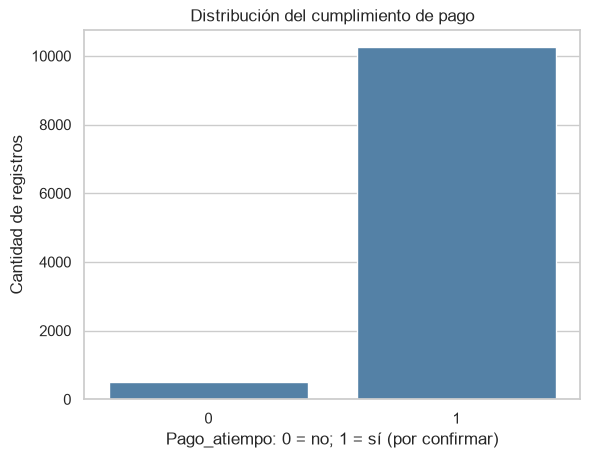

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

conteos = df["Pago_atiempo"].value_counts().sort_index()

tabla_objetivo = pd.DataFrame({
    "cantidad": conteos,
    "porcentaje": (conteos / len(df) * 100).round(2)
})

display(tabla_objetivo)

sns.countplot(data=df, x="Pago_atiempo", color="steelblue")

plt.title("Distribución del cumplimiento de pago")
plt.xlabel("Pago_atiempo: 0 = no; 1 = sí (por confirmar)")
plt.ylabel("Cantidad de registros")
plt.show()

### Distribución de la variable objetivo

Existe un fuerte desbalance entre las clases: el 95,25 % de los
registros pertenece a la clase 1 y el 4,75 % a la clase 0.

Un modelo que siempre predijera la clase 1 alcanzaría aproximadamente
95,25 % de exactitud, pero no identificaría ningún caso de la clase 0.
Por ello, en la etapa de modelado será necesario evaluar métricas
por clase y no depender únicamente de la exactitud.

In [9]:
numericas = df.select_dtypes(include="number").columns.tolist()

estadisticas = df[numericas].describe().T

estadisticas["rango"] = (
    estadisticas["max"] - estadisticas["min"]
)

estadisticas["IQR"] = (
    estadisticas["75%"] - estadisticas["25%"]
)

estadisticas["varianza"] = df[numericas].var()
estadisticas["asimetria"] = df[numericas].skew()
estadisticas["curtosis"] = df[numericas].kurt()

estadisticas["moda"] = df[numericas].apply(
    lambda serie: serie.mode().iloc[0]
    if not serie.mode().empty else np.nan
)

display(estadisticas.round(2))

,count,mean,std,min,25%,50%,75%,max,rango,IQR,varianza,asimetria,curtosis,moda
capital_prestado,10763.0,2434315.00,1.909643e+06,360000.00,1224831.00,1921920.00,3084840.00,4.144415e+07,4.108415e+07,1860009.00,3.646735e+12,3.72,35.32,1200000.00
plazo_meses,10763.0,10.58,6.630000e+00,2.00,6.00,10.00,12.00,9.000000e+01,8.800000e+01,6.00,4.398000e+01,2.46,7.78,6.00
edad_cliente,10763.0,43.95,1.506000e+01,19.00,33.00,42.00,53.00,1.230000e+02,1.040000e+02,20.00,2.268300e+02,1.93,7.87,40.00
salario_cliente,10763.0,17216431.46,3.554767e+08,0.00,2000000.00,3000000.00,4875808.00,2.200000e+10,2.200000e+10,2875808.00,1.263637e+17,43.78,2211.23,3000000.00
total_otros_prestamos,10763.0,6238869.65,1.184183e+08,0.00,500000.00,1000000.00,2000000.00,6.787675e+09,6.787675e+09,1500000.00,1.402290e+16,38.46,1719.28,2000000.00
cuota_pactada,10763.0,243617.41,2.104937e+05,23944.00,121041.50,182863.00,287833.50,3.816752e+06,3.792808e+06,166792.00,4.430760e+10,3.79,26.65,205990.00
puntaje,10763.0,91.17,1.647000e+01,-38.01,95.23,95.23,95.23,9.523000e+01,1.332400e+02,0.00,2.711100e+02,-4.87,24.08,95.23
puntaje_datacredito,10757.0,780.79,1.048800e+02,-7.00,757.00,791.00,825.00,9.990000e+02,1.006000e+03,68.00,1.099940e+04,-5.64,39.44,0.00
cant_creditosvigentes,10763.0,5.73,3.980000e+00,0.00,3.00,5.00,8.00,6.200000e+01,6.200000e+01,5.00,1.582000e+01,1.80,8.62,4.00
huella_consulta,10763.0,4.23,3.060000e+00,0.00,2.00,4.00,6.00,2.900000e+01,2.900000e+01,4.00,9.390000e+00,1.49,4.00,2.00


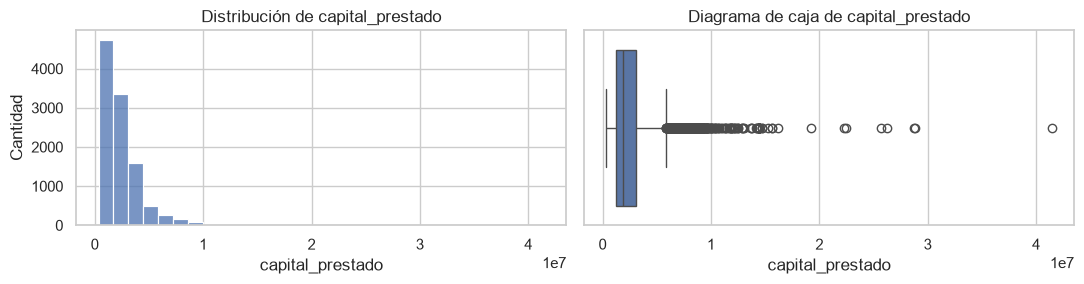

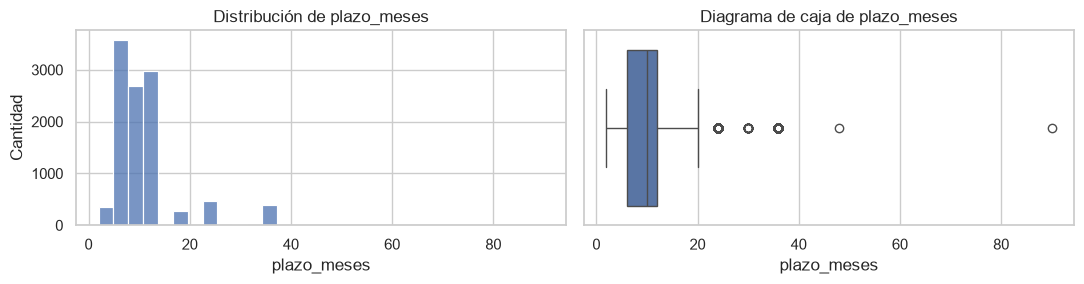

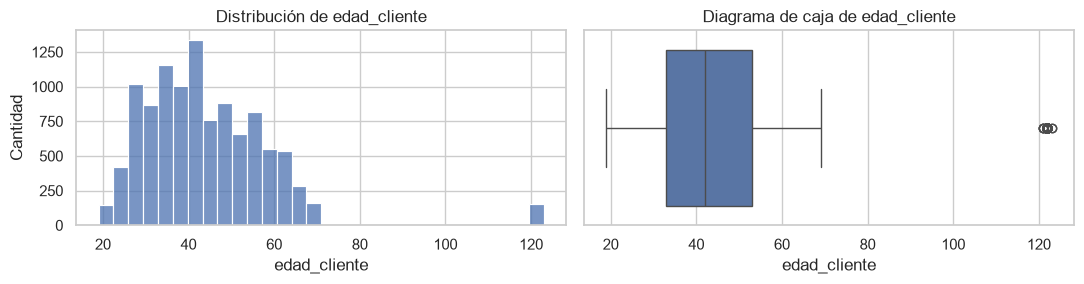

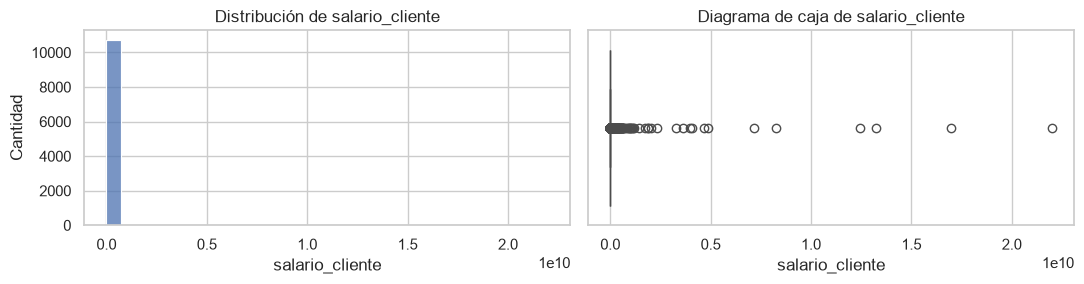

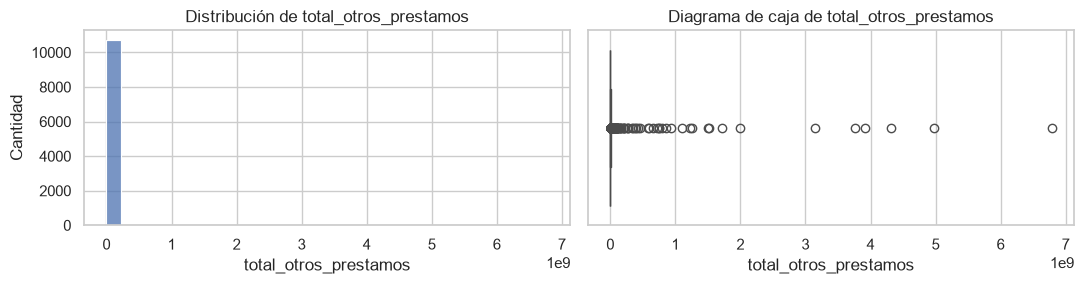

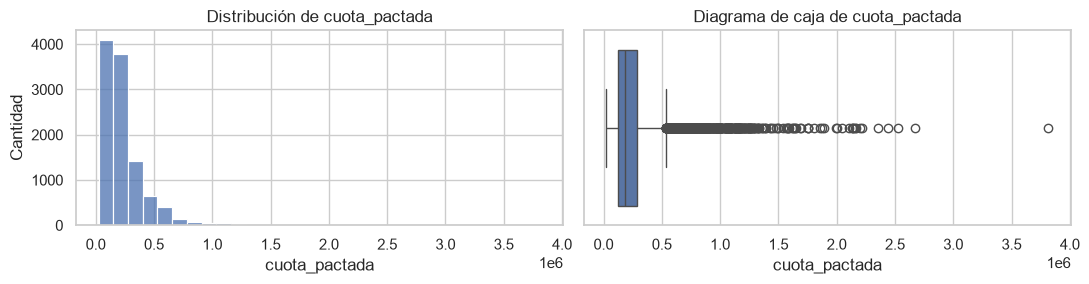

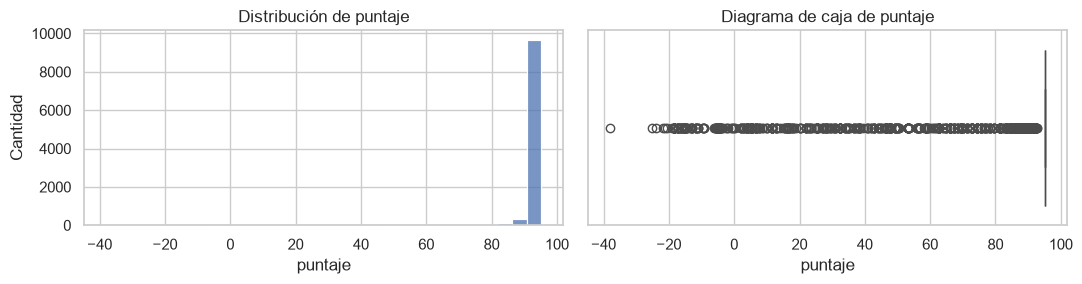

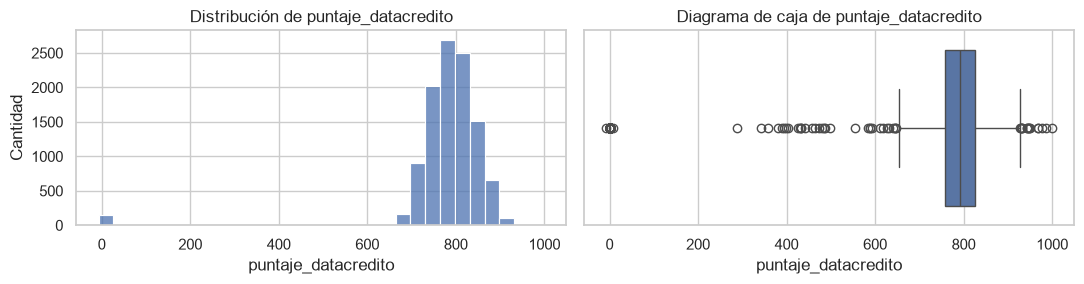

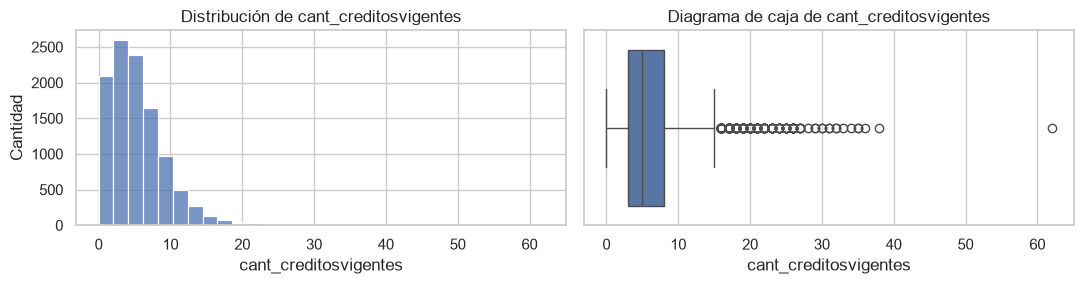

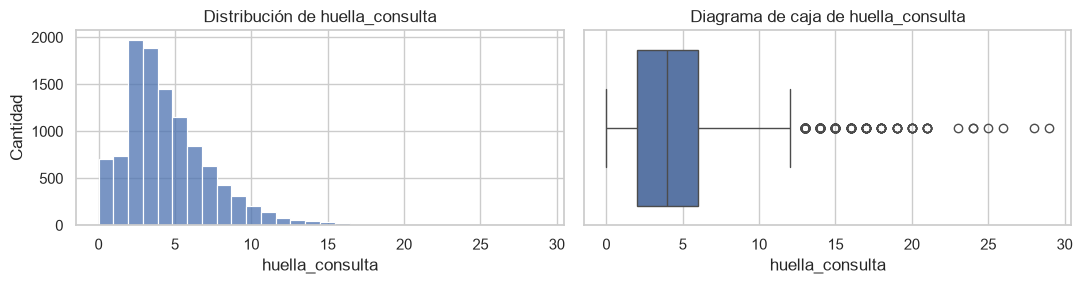

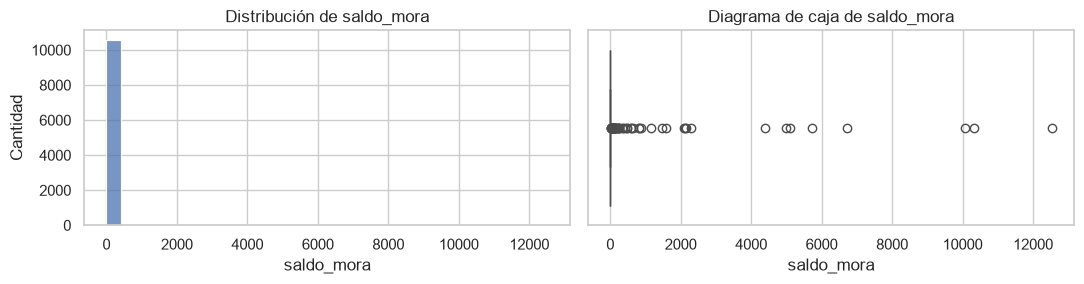

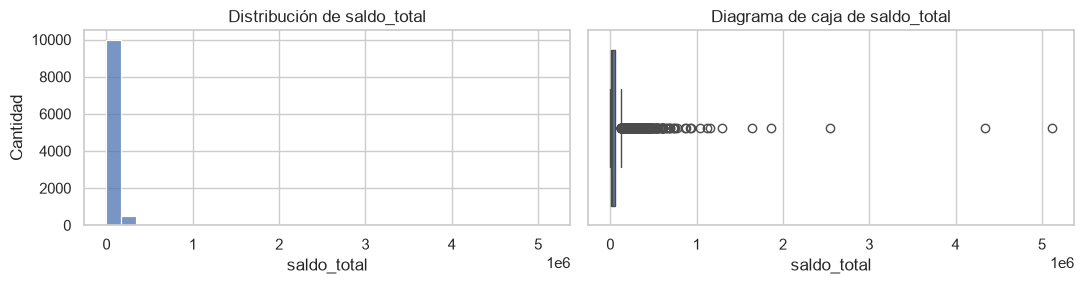

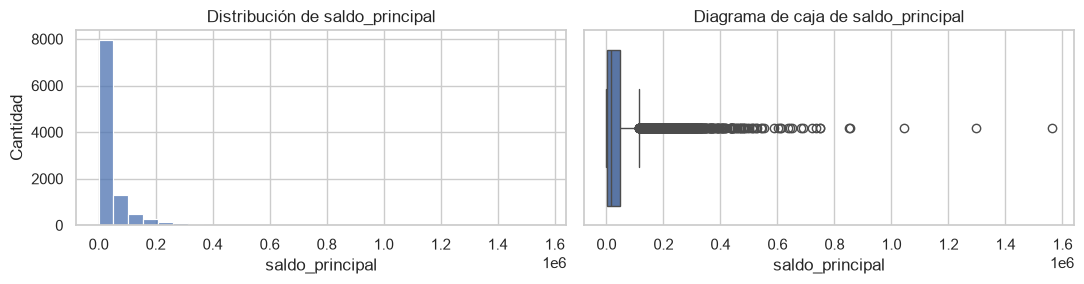

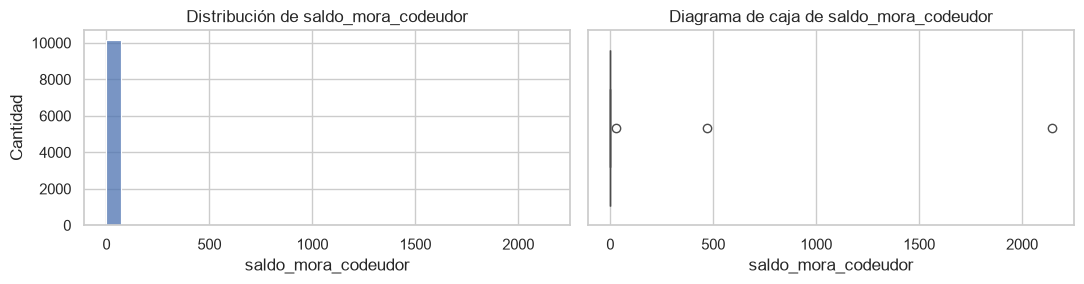

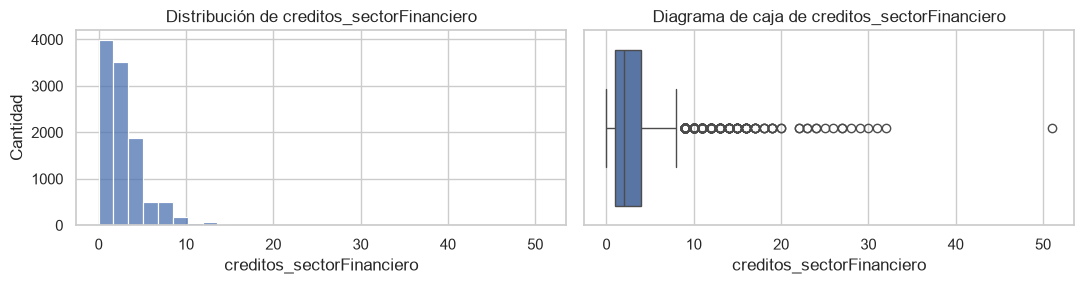

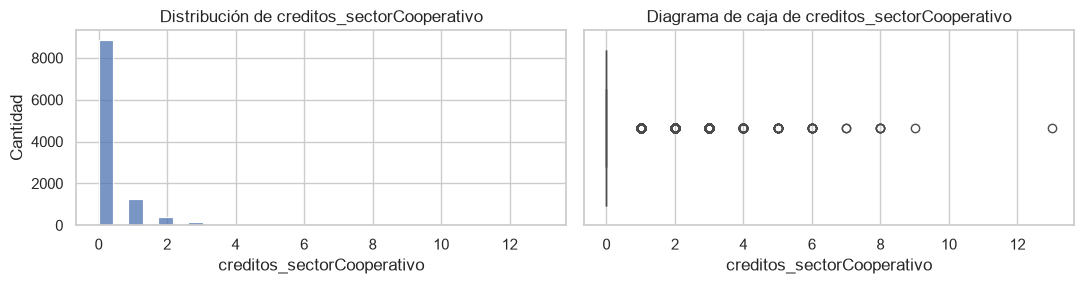

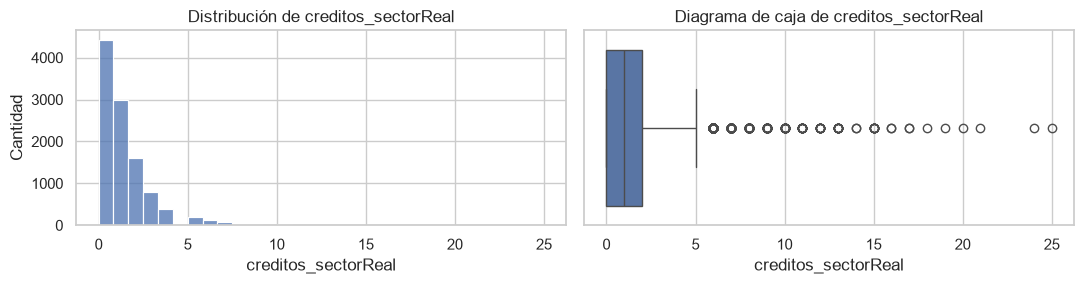

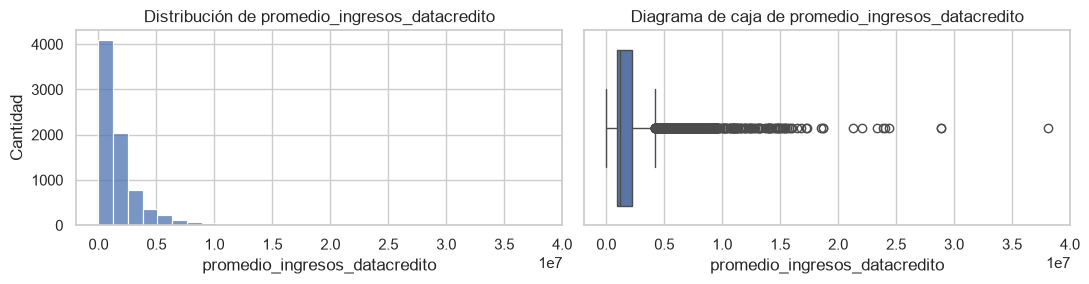

In [10]:
for columna in numericas:
    valores = df[columna].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(11, 3))

    sns.histplot(x=valores, bins=30, ax=axes[0])
    axes[0].set_title(f"Distribución de {columna}")
    axes[0].set_ylabel("Cantidad")

    sns.boxplot(x=valores, ax=axes[1])
    axes[1].set_title(f"Diagrama de caja de {columna}")

    plt.tight_layout()
    plt.show()

,cantidad,porcentaje
tipo_credito,,
4,7747,71.98
9,2876,26.72
10,116,1.08
6,21,0.2
7,2,0.02
68,1,0.01


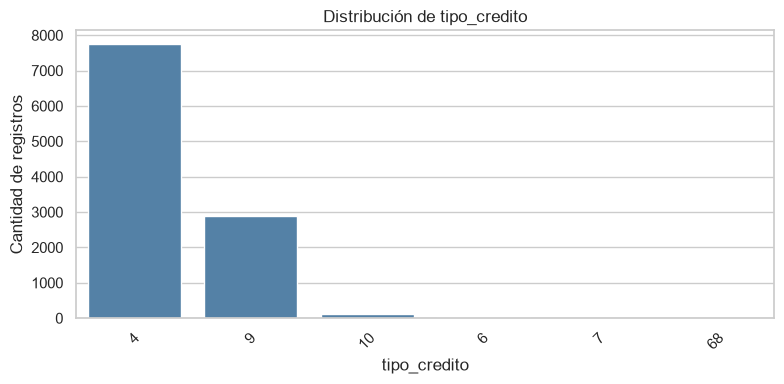

,cantidad,porcentaje
tipo_laboral,,
Empleado,6754,62.75
Independiente,4009,37.25


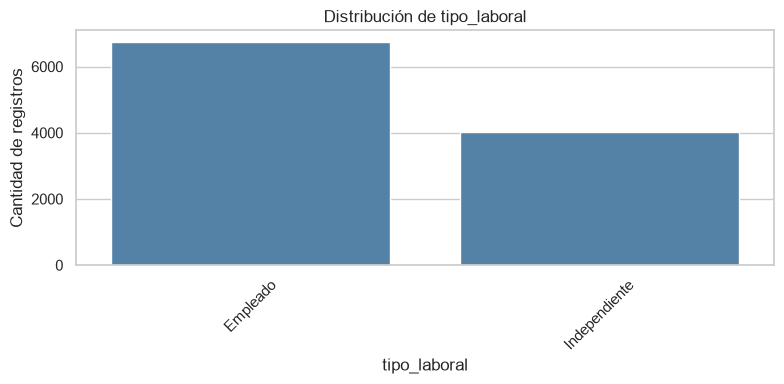

,cantidad,porcentaje
tendencia_ingresos,,
Creciente,5294,49.19
Sin información,2990,27.78
Decreciente,1291,11.99
Estable,1188,11.04


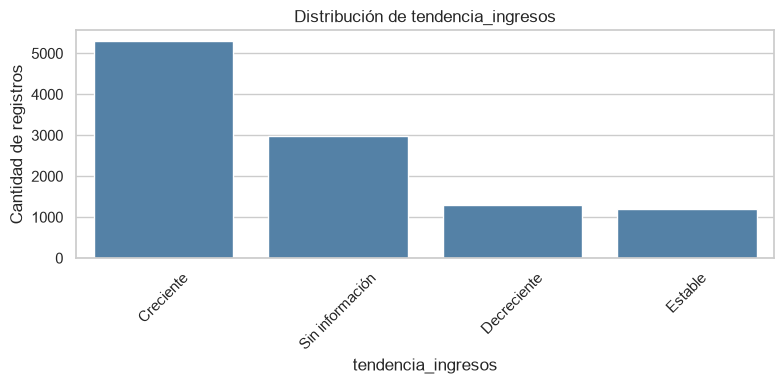

In [11]:
categoricas = [
    "tipo_credito",
    "tipo_laboral",
    "tendencia_ingresos"
]

for columna in categoricas:
    # Mostrar los faltantes como una categoría solo para visualizar.
    valores = df[columna].astype("string").fillna("Sin información")

    conteos = valores.value_counts()

    display(pd.DataFrame({
        "cantidad": conteos,
        "porcentaje": (conteos / len(df) * 100).round(2)
    }))

    plt.figure(figsize=(8, 4))

    sns.countplot(
        x=valores,
        order=conteos.index,
        color="steelblue"
    )

    plt.title(f"Distribución de {columna}")
    plt.xlabel(columna)
    plt.ylabel("Cantidad de registros")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Hallazgos del análisis univariable

El tipo de crédito 4 es el más frecuente, seguido por el tipo 9.
Algunas categorías tienen muy pocos registros, por lo que sus
resultados deberán interpretarse con precaución.

En tipo_laboral predominan los empleados sobre los independientes.
En tendencia_ingresos predomina la categoría Creciente entre los
registros con información válida, aunque existe una proporción
importante de datos faltantes.

Las variables monetarias requieren atención a los valores extremos.
Por ejemplo, salario_cliente presenta una media cercana a 17,2
millones y una mediana de 3 millones. Esta diferencia indica que
los valores altos influyen considerablemente en el promedio.

La variable puntaje concentra gran parte de sus registros en un
mismo valor. Su utilidad predictiva deberá evaluarse posteriormente.

Los gráficos permiten describir las distribuciones, pero no bastan
para afirmar que siguen una distribución teórica específica.
No se eliminan valores atípicos únicamente por aparecer fuera
de los límites de un boxplot.

## 5. Análisis bivariable

Se comparan las características de los registros según Pago_atiempo
para explorar asociaciones con el cumplimiento de pago.

Debido al desbalance de clases, se utilizan porcentajes dentro
de cada categoría y estadísticas por grupo. Las asociaciones
observadas no demuestran causalidad.


Análisis de: tipo_credito
Cantidad de registros:


Pago_atiempo,0,1
tipo_credito,,
10,3,113
4,363,7384
6,9,12
68,0,1
7,0,2
9,136,2740


Porcentaje dentro de cada categoría:


Pago_atiempo,0,1
tipo_credito,,
10,2.59,97.41
4,4.69,95.31
6,42.86,57.14
68,0.00,100.00
7,0.00,100.00
9,4.73,95.27


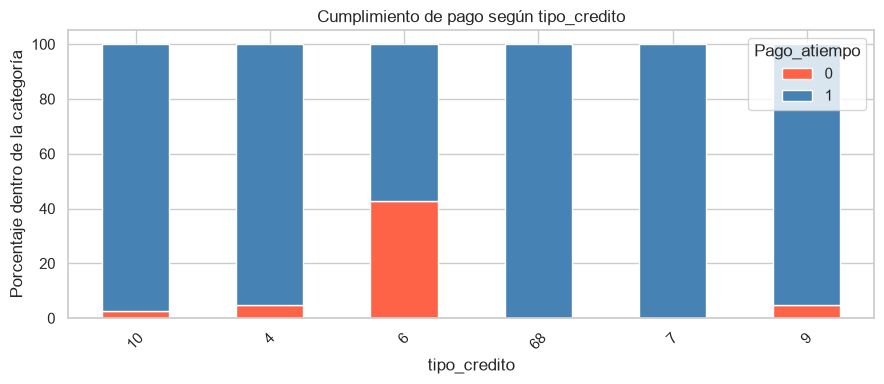


Análisis de: tipo_laboral
Cantidad de registros:


Pago_atiempo,0,1
tipo_laboral,,
Empleado,290,6464
Independiente,221,3788


Porcentaje dentro de cada categoría:


Pago_atiempo,0,1
tipo_laboral,,
Empleado,4.29,95.71
Independiente,5.51,94.49


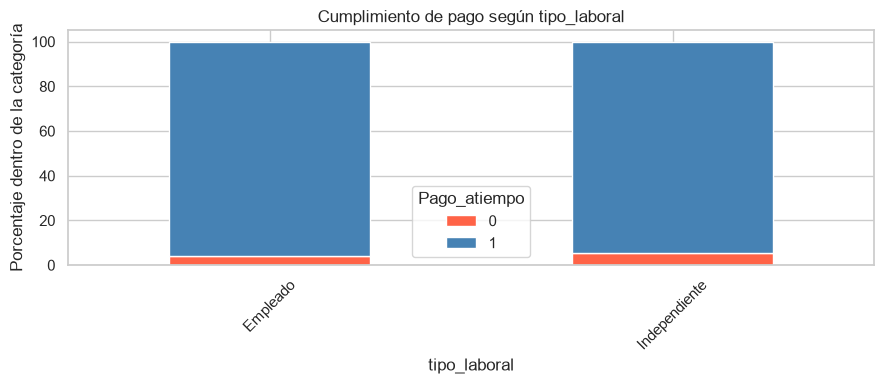


Análisis de: tendencia_ingresos
Cantidad de registros:


Pago_atiempo,0,1
tendencia_ingresos,,
Creciente,207,5087
Decreciente,81,1210
Estable,55,1133
Sin información,168,2822


Porcentaje dentro de cada categoría:


Pago_atiempo,0,1
tendencia_ingresos,,
Creciente,3.91,96.09
Decreciente,6.27,93.73
Estable,4.63,95.37
Sin información,5.62,94.38


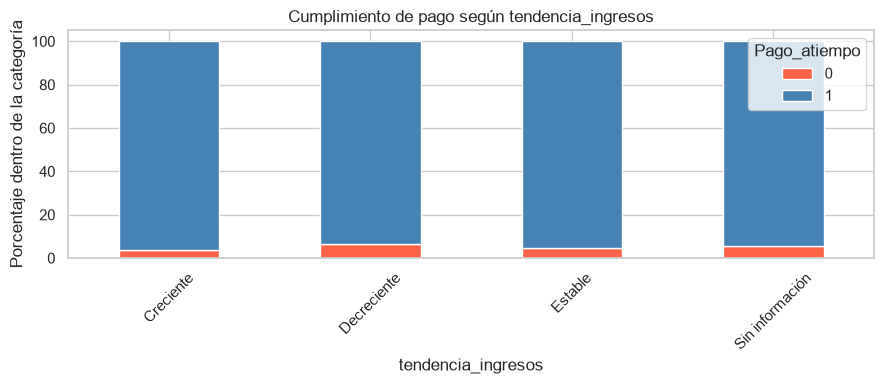

In [12]:
for columna in categoricas:
    valores = df[columna].astype("string").fillna("Sin información")

    cantidades = pd.crosstab(valores, df["Pago_atiempo"])
    porcentajes = pd.crosstab(
        valores,
        df["Pago_atiempo"],
        normalize="index"
    ).mul(100)

    print(f"\nAnálisis de: {columna}")
    print("Cantidad de registros:")
    display(cantidades)

    print("Porcentaje dentro de cada categoría:")
    display(porcentajes.round(2))

    porcentajes.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 4),
        color=["tomato", "steelblue"]
    )

    plt.title(f"Cumplimiento de pago según {columna}")
    plt.xlabel(columna)
    plt.ylabel("Porcentaje dentro de la categoría")
    plt.legend(title="Pago_atiempo")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [13]:
resumen_por_pago = df.groupby(
    "Pago_atiempo",
    observed=True
)[numericas].agg(["count", "mean", "median", "std"])

display(resumen_por_pago.round(2).T)

Pago_atiempo                                   0           1
capital_prestado              count       511.00    10252.00
                              mean    2781774.11  2416996.27
                              median  2268000.00  1908446.40
                              std     1942337.70  1906438.41
plazo_meses                   count       511.00    10252.00
...                                          ...         ...
creditos_sectorReal           std           2.05        1.81
promedio_ingresos_datacredito count       343.00     7490.00
                              mean    1605742.05  2023447.77
                              median  1052529.00  1211296.00
                              std     1668892.06  2161702.28

[72 rows x 2 columns]

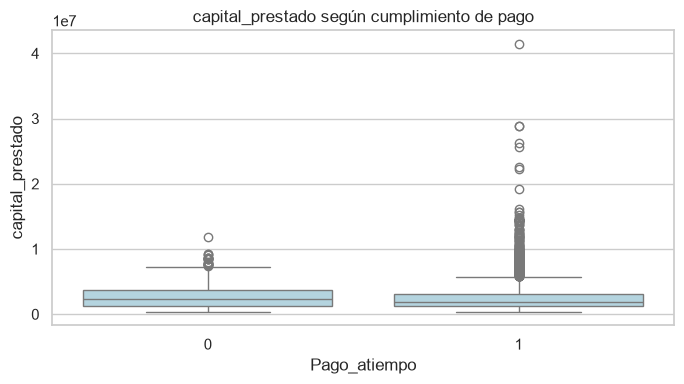

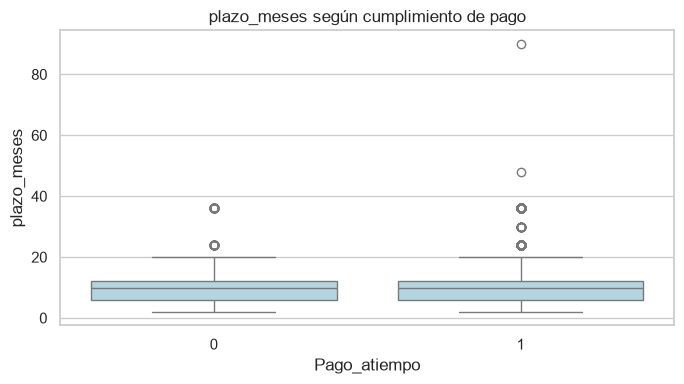

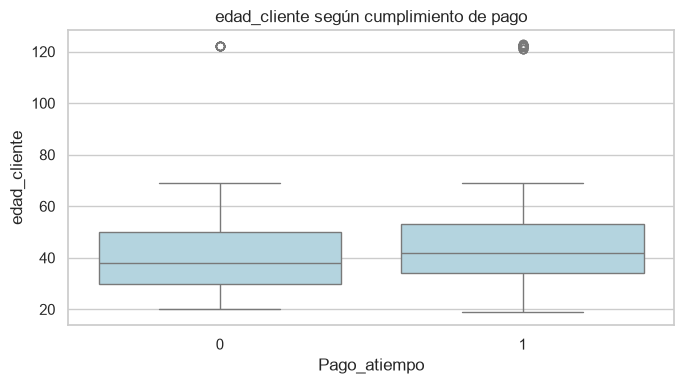

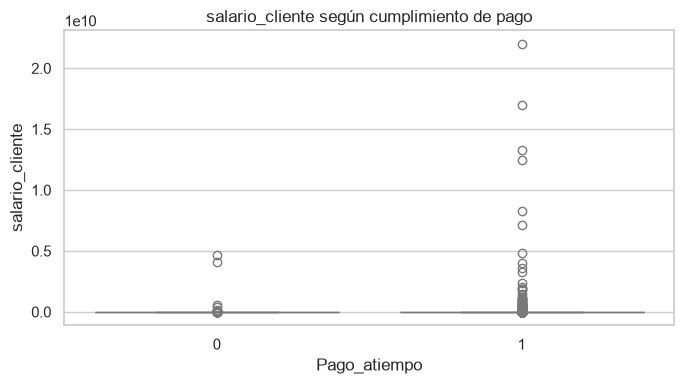

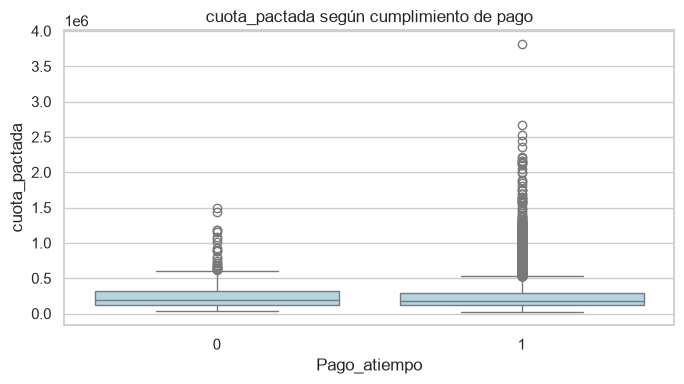

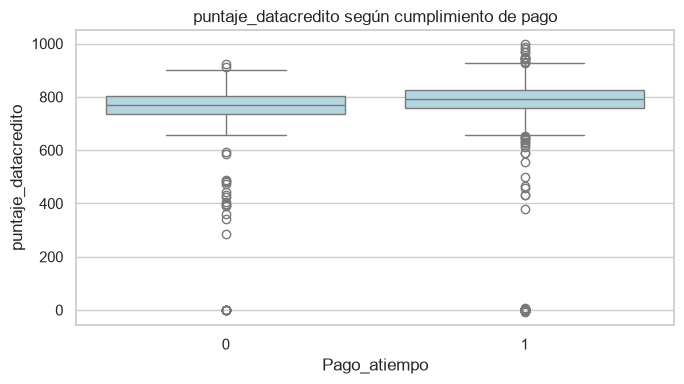

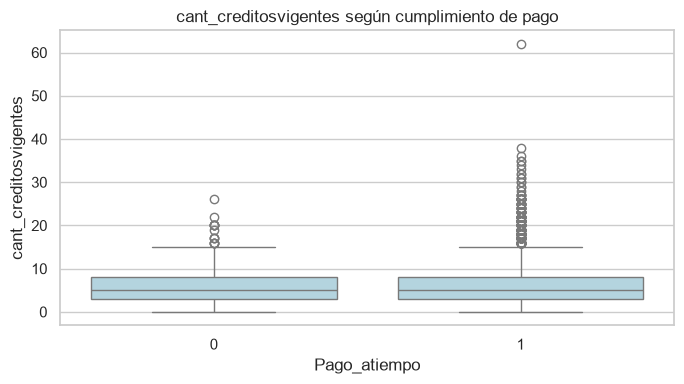

In [14]:
comparar = [
    "capital_prestado",
    "plazo_meses",
    "edad_cliente",
    "salario_cliente",
    "cuota_pactada",
    "puntaje_datacredito",
    "cant_creditosvigentes"
]

for columna in comparar:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Pago_atiempo",
        y=columna,
        color="lightblue"
    )

    plt.title(f"{columna} según cumplimiento de pago")
    plt.xlabel("Pago_atiempo")
    plt.ylabel(columna)
    plt.tight_layout()
    plt.show()

In [15]:
medianas = df.groupby(
    "Pago_atiempo",
    observed=True
)[comparar].median().T

medianas.columns = [
    f"Mediana clase {clase}" for clase in medianas.columns
]

display(medianas.round(2))

,Mediana clase 0,Mediana clase 1
capital_prestado,2268000.0,1908446.4
plazo_meses,10.0,10.0
edad_cliente,38.0,42.0
salario_cliente,3000000.0,3000000.0
cuota_pactada,199002.0,182576.0
puntaje_datacredito,768.0,792.0
cant_creditosvigentes,5.0,5.0


### Hallazgos de la comparación de medianas

Considerando provisionalmente que 0 significa no pagar a tiempo
y 1 pagar a tiempo, se observan las siguientes diferencias:

- El capital prestado presenta una mediana mayor en la clase 0:
  2.268.000 frente a 1.908.446,40 en la clase 1.

- La cuota pactada también tiene una mediana mayor en la clase 0:
  199.002 frente a 182.576 en la clase 1.

- La edad mediana es de 38 años en la clase 0 y de 42 años
  en la clase 1.

- El puntaje de Datacrédito presenta una mediana de 768
  en la clase 0 y de 792 en la clase 1.

- Ambas clases comparten las medianas de plazo del crédito
  (10 meses), salario reportado (3.000.000) y cantidad de
  créditos vigentes (5).

Estas diferencias describen asociaciones entre los grupos;
no demuestran que una característica cause el incumplimiento.
Además, compartir una mediana no significa tener distribuciones
idénticas ni descarta la utilidad de una variable.

La interpretación debe considerar el desbalance de clases,
los valores faltantes y las inconsistencias pendientes de validación.
Las unidades monetarias deben confirmarse con la fuente.

### Interpretación del análisis bivariable

Las tablas de porcentajes permiten comparar el cumplimiento
de pago entre categorías sin confundirlo con su tamaño.

Las medianas y los diagramas de caja permiten explorar diferencias
en las características numéricas entre ambas clases. Los valores
extremos y las inconsistencias pendientes de validación deben
considerarse al interpretar estas diferencias.

Las categorías con pocos registros presentan porcentajes poco
estables. Asimismo, las diferencias observadas no permiten afirmar
que una característica cause el incumplimiento.

Antes de utilizar los saldos y puntajes como predictores, se debe
confirmar que fueron medidos antes del resultado que se quiere
predecir, para evitar fuga de información.

## 6. Análisis multivariable

Se exploran relaciones entre características numéricas y combinaciones
de categorías, considerando también Pago_atiempo.

Este análisis permite identificar asociaciones, posibles variables
redundantes y patrones que deberán evaluarse durante el modelado.
Las relaciones encontradas no demuestran causalidad.

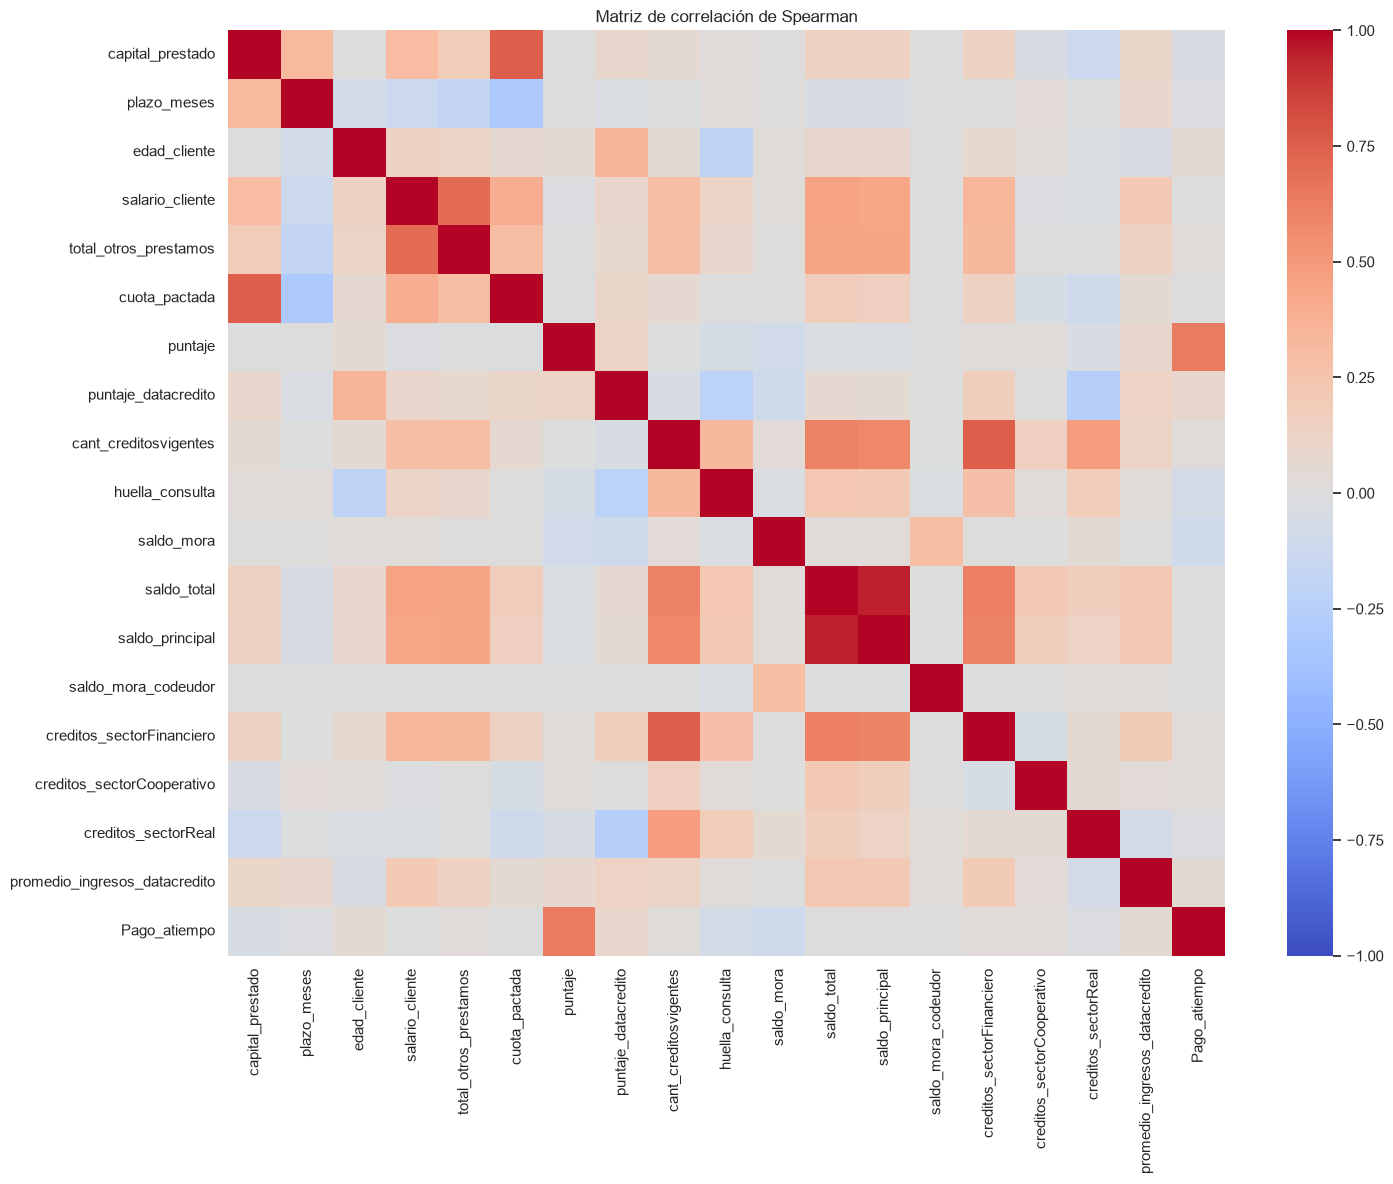

Correlaciones con la variable objetivo:


,Correlación
puntaje,0.639
saldo_mora,-0.108
puntaje_datacredito,0.091
huella_consulta,-0.073
promedio_ingresos_datacredito,0.051
edad_cliente,0.051
capital_prestado,-0.042
creditos_sectorFinanciero,0.030
total_otros_prestamos,0.026
creditos_sectorCooperativo,0.024


In [16]:
# Pago_atiempo se convierte a número únicamente en esta copia.
datos_correlacion = df[numericas].copy()

datos_correlacion["Pago_atiempo"] = (
    df["Pago_atiempo"].astype("int64")
)

correlacion = datos_correlacion.corr(method="spearman")

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlacion,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()

print("Correlaciones con la variable objetivo:")

correlacion_objetivo = (
    correlacion["Pago_atiempo"]
    .drop("Pago_atiempo")
    .dropna()
    .sort_values(key=lambda valores: valores.abs(), ascending=False)
)

display(correlacion_objetivo.round(3).to_frame("Correlación"))

### Hallazgos de las correlaciones con Pago_atiempo

La variable puntaje presenta la mayor correlación de Spearman
con Pago_atiempo (0,639). Los puntajes más altos tienden a asociarse
con la clase 1, interpretada provisionalmente como pago a tiempo.

Este resultado requiere revisar cómo se calcula puntaje y cuándo
se obtiene. Si incorpora el comportamiento de pago que se busca
predecir, existiría fuga de información. La correlación no confirma
por sí sola ese problema ni garantiza utilidad predictiva.

saldo_mora presenta una asociación negativa débil (-0,108):
los saldos de mora más altos tienden a asociarse con la clase 0.
También debe confirmarse que este saldo se conocía antes del
resultado que se desea predecir.

Las demás variables presentan correlaciones de magnitud inferior
a 0,10 con el objetivo. Por ejemplo, puntaje_datacredito alcanza
0,091 y huella_consulta -0,073.

Una correlación cercana a cero no demuestra que una variable
sea inútil: podría aportar información mediante relaciones no
monotónicas o combinaciones con otras características.

Estos resultados describen asociaciones, no relaciones causales.
No se eliminan variables ni se seleccionan modelos en esta etapa.

In [17]:
# Revisar asociaciones entre predictores, sin incluir el objetivo.
corr_predictores = correlacion.drop(
    index="Pago_atiempo",
    columns="Pago_atiempo"
)

parejas = []

columnas = corr_predictores.columns

for i in range(len(columnas)):
    for j in range(i + 1, len(columnas)):
        valor = corr_predictores.iloc[i, j]

        if pd.notna(valor) and abs(valor) >= 0.80:
            parejas.append({
                "variable_1": columnas[i],
                "variable_2": columnas[j],
                "correlacion": valor
            })

parejas_altas = pd.DataFrame(
    parejas,
    columns=["variable_1", "variable_2", "correlacion"]
)

if parejas_altas.empty:
    print("No se encontraron parejas con |correlación| >= 0.80.")
else:
    display(
        parejas_altas.sort_values(
            "correlacion",
            key=lambda valores: valores.abs(),
            ascending=False
        ).round(3)
    )

,variable_1,variable_2,correlacion
0,saldo_total,saldo_principal,0.946


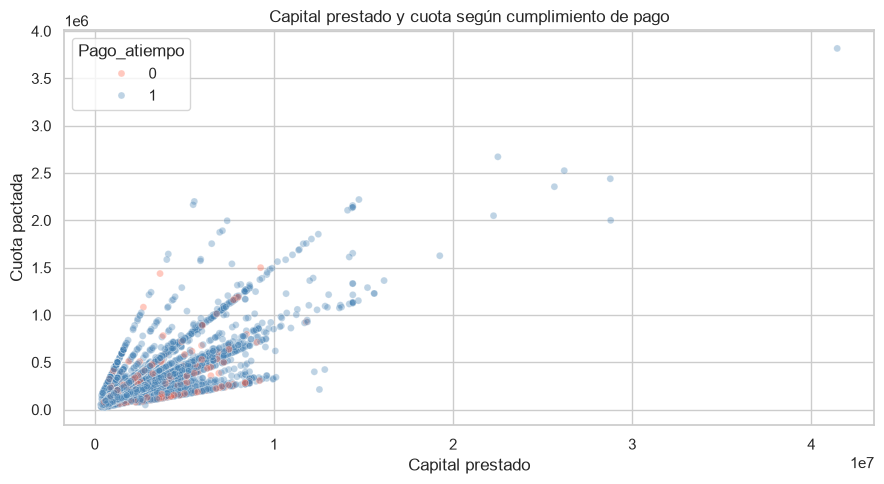

In [18]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="capital_prestado",
    y="cuota_pactada",
    hue="Pago_atiempo",
    hue_order=[0, 1],
    palette={0: "tomato", 1: "steelblue"},
    alpha=0.35,
    s=25
)

plt.title("Capital prestado y cuota según cumplimiento de pago")
plt.xlabel("Capital prestado")
plt.ylabel("Cuota pactada")
plt.tight_layout()
plt.show()

In [19]:
tabla_combinada = (
    df.groupby(
        ["tipo_laboral", "tipo_credito"],
        observed=True
    )["Pago_atiempo"]
    .agg(
        registros="size",
        casos_clase_0=lambda serie: (serie == 0).sum()
    )
    .reset_index()
)

tabla_combinada["porcentaje_clase_0"] = (
    tabla_combinada["casos_clase_0"]
    / tabla_combinada["registros"]
    * 100
)

display(tabla_combinada.round(2))

,tipo_laboral,tipo_credito,registros,casos_clase_0,porcentaje_clase_0
0,Empleado,4,5052,209,4.14
1,Empleado,6,21,9,42.86
2,Empleado,7,1,0,0.00
3,Empleado,9,1604,70,4.36
4,Empleado,10,75,2,2.67
5,Empleado,68,1,0,0.00
6,Independiente,4,2695,154,5.71
7,Independiente,7,1,0,0.00
8,Independiente,9,1272,66,5.19
9,Independiente,10,41,1,2.44


### Interpretación del análisis multivariable

La matriz de Spearman permite explorar asociaciones monotónicas
entre variables numéricas. Las parejas con una correlación absoluta
igual o superior a 0,80 se señalan para revisar posible redundancia,
sin eliminar variables automáticamente.

El gráfico de dispersión permite examinar conjuntamente el capital,
la cuota pactada y el cumplimiento de pago. El desbalance de clases
puede dificultar la identificación visual de la clase minoritaria.

La tabla por tipo laboral y tipo de crédito permite explorar
diferencias entre grupos. Los porcentajes de combinaciones con
pocos registros deben interpretarse con precaución.

Estos resultados describen asociaciones y deberán complementarse
con la validación de calidad, significado y disponibilidad temporal
de las variables.

## 7. Reglas de validación propuestas

Las siguientes reglas se plantean a partir de la exploración.
Las reglas de negocio pendientes deben confirmarse con la fuente
antes de utilizarlas para eliminar o modificar registros.

| Variable o grupo | Regla propuesta | Tratamiento |
|---|---|---|
| Pago_atiempo | Debe estar completa y contener únicamente 0 o 1 | Reportar cualquier incumplimiento |
| fecha_prestamo | Debe poder interpretarse como fecha | Reportar fechas inválidas y confirmar el periodo esperado |
| tipo_credito | Debe pertenecer al catálogo autorizado | Confirmar los códigos, especialmente los poco frecuentes |
| tipo_laboral | Validar contra el catálogo de categorías | Revisar categorías diferentes de las observadas |
| tendencia_ingresos | Categorías provisionales: Creciente, Decreciente y Estable | Tratar otros valores como faltantes mientras se validan |
| capital_prestado, cuota_pactada y plazo_meses | Se espera que sean positivos | Revisar valores iguales o inferiores a cero |
| Conteos de créditos y consultas | Se espera que sean enteros no negativos | Reportar valores incompatibles |
| edad_cliente | Revisar edades fuera del rango permitido por la entidad | Conservar los casos señalados hasta validarlos |
| Variables monetarias | Confirmar unidades y significado de los ceros | No confundir cero con información desconocida |
| Puntajes | Confirmar escala y códigos especiales | Revisar valores negativos sin corregirlos automáticamente |
| Filas duplicadas | Identificar coincidencias completas | Investigar antes de eliminar, pues no existe un identificador único confirmado |
| Variables predictoras | Deben estar disponibles al momento de la predicción | Excluir del futuro modelo la información posterior al resultado |

Los valores extremos se consideran alertas de revisión, no errores
confirmados. Los valores faltantes no se reemplazan automáticamente
por cero.

## 8. Revisión de relevancia de las variables

No se eliminan columnas en esta etapa porque no se ha demostrado
que sean irrelevantes.

tipo_credito se conserva como categoría: sus códigos no representan
una magnitud numérica.

fecha_prestamo se conserva para estudiar el periodo de los registros
y proponer posteriormente características temporales.

puntaje presenta una fuerte concentración en un mismo valor.
Esto justifica evaluar su utilidad, pero no eliminarlo sin más análisis.

Los saldos y puntajes requieren confirmar su momento de medición.
Si incluyen información obtenida después del pago que se desea
predecir, deberán excluirse como predictores para evitar fuga
de información.

También es necesario confirmar la definición de Pago_atiempo,
el periodo observado y si varios créditos pertenecen al mismo
cliente. Sin un identificador confirmado no puede evaluarse
completamente esta última situación.

## 9. Transformaciones y atributos derivados propuestos

Las siguientes propuestas se documentan para etapas posteriores.
No se implementan como parte de esta entrega.

| Propuesta | Propósito | Precaución |
|---|---|---|
| Imputación de variables numéricas | Tratar información faltante | Elegir el método según su significado y ajustarlo solo con entrenamiento |
| Categoría de información desconocida | Representar faltantes categóricos | No confundir desconocido con una categoría real |
| Codificación de categorías | Preparar variables categóricas para ciertos modelos | Evitar asignar orden artificial a categorías nominales |
| Transformación logarítmica | Explorar montos con fuerte asimetría | Comprobar valores negativos y ceros |
| Escalamiento | Preparar variables para modelos sensibles a las escalas | Ajustarlo solo con entrenamiento |
| Indicadores de datos faltantes | Evaluar si la ausencia de información aporta una señal | Revisar su estabilidad y disponibilidad |
| Relación cuota/salario | Explorar el peso de la cuota respecto al salario reportado | Definir el tratamiento de salarios iguales a cero |
| Año y mes del préstamo | Explorar patrones temporales | Considerar que el historial cubre un periodo limitado |

No se aplicará balanceo de clases en el EDA. Su necesidad se
evaluará durante el modelado, manteniendo los datos de evaluación
con una distribución representativa.

## 10. Conclusiones del análisis exploratorio

1. La base contiene 10.763 registros y 23 variables. No se encontraron
   filas completamente duplicadas.

2. Pago_atiempo presenta un fuerte desbalance: 10.252 registros
   pertenecen a la clase 1 y 511 a la clase 0. Por tanto, la exactitud
   por sí sola no será suficiente para evaluar los futuros modelos.

3. Se identificaron valores faltantes en varias columnas.
   promedio_ingresos_datacredito presenta 2.930 faltantes.
   tendencia_ingresos pasó de 2.932 a 2.990 faltantes después de
   tratar provisionalmente 58 valores inesperados como desconocidos.

4. Se encontraron 150 edades superiores a 100 años, 24 salarios
   iguales a cero y un puntaje de Datacrédito negativo. Estos casos
   requieren validación; no se eliminaron automáticamente.

5. salario_cliente presenta una media aproximada de 17,2 millones
   y una mediana de 3 millones. La diferencia muestra la influencia
   de los valores elevados y la necesidad de revisar su distribución
   y sus unidades.

6. Los análisis bivariable y multivariable permiten explorar
   asociaciones, pero no demuestran causalidad. Sus hallazgos
   específicos deben interpretarse considerando los tamaños
   de los grupos, los faltantes y los valores extremos.

7. Antes del modelado se requiere confirmar la definición del
   objetivo, las unidades monetarias y la disponibilidad temporal
   de saldos y puntajes.

El alcance de esta entrega comprende carga, comprensión,
exploración y preparación inicial de los datos. No incluye
entrenamiento, selección de modelos ni despliegue.